In [12]:
from PIL import Image
from tqdm import tqdm
import glob
import matplotlib.pyplot as plt
import numpy as np
import os

In [13]:
def get_n_primes(n):
    assert n >= 1, "n must be at least 1"
    i = 2
    lst = [2]
    while len(lst) < n:
        if any([i % p == 0 for p in lst]):
            i += 1
        else:
            lst.append(i)
    return np.array(lst)


def find_surpass_index(col_sums, row_sums):
    for i in range(len(col_sums)):
        if col_sums[i] > row_sums[i]:
            return i - 1
    return -1

In [19]:
ratios_1 = []
ratios_2 = []

for N in tqdm(range(2, 2000, 10)):
    primes = get_n_primes(N)
    primes_mod_2d = np.array([[j % i if j > i else 0 for j in primes] for i in primes])
    row_sums = np.sum(primes_mod_2d, axis=1)
    col_sums = np.sum(primes_mod_2d, axis=0)
    plt.plot(row_sums, label='Row Sums')
    plt.plot(col_sums, label='Col Sums')
    idx = find_surpass_index(col_sums, row_sums)
    row_max = np.max(row_sums)
    plt.axvline(idx, color='r', linestyle='--', label='Surpass Index')
    plt.axhline(row_max, color='b', linestyle='--', label='Max Value')
    plt.legend(loc='best')
    plt.savefig(f"./output/img_{str(N).zfill(5)}.png")
    plt.clf()
    ratios_1.append(idx / N)
    ratios_2.append(row_max / np.max(col_sums))

  0%|          | 0/200 [00:00<?, ?it/s]

100%|██████████| 200/200 [00:57<00:00,  3.47it/s]


<Figure size 640x480 with 0 Axes>

In [20]:
image_paths = glob.glob(os.path.join("./output", "img_*.png"))
image_paths.sort()
# image_paths += image_paths[::-1]
images = [Image.open(image) for image in image_paths]

images[0].save(
    os.path.join("./output", "graph_mini.gif"),
    save_all=True,
    append_images=images[1:],
    loop=0,
    duration=0.1,
)

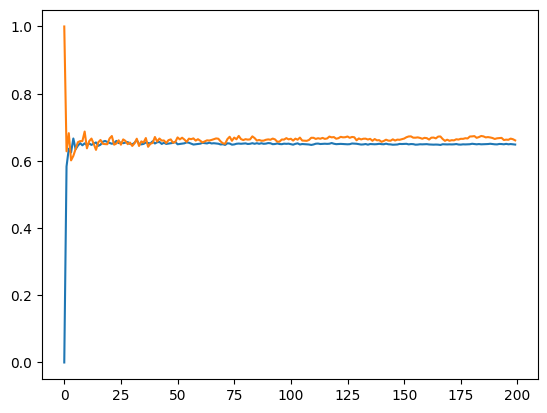

In [21]:
plt.plot(ratios_1)
plt.plot(ratios_2)